In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the original NASA dataset
df = pd.read_csv("data/fire_data.csv", skiprows=8)

# Preview the dataset
df.head()

,YEAR,MO,DY,T2M_MAX_SSP126,T2M_MAX_SSP245,T2M_MAX_SSP370
0,2015,1,1,15.03,15.17,15.19
1,2015,1,2,16.02,15.94,15.85
2,2015,1,3,16.34,16.23,16.27
3,2015,1,4,15.73,15.66,15.72
4,2015,1,5,16.50,16.75,16.59


In [2]:
# Dataset dimensions
print("Shape:", df.shape)

# Column information
df.info()

# Summary statistics
display(df.describe())

# Missing values
print(df.isna().sum())


Shape: (31411, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31411 entries, 0 to 31410
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   YEAR            31411 non-null  int64  
 1   MO              31411 non-null  int64  
 2   DY              31411 non-null  int64  
 3   T2M_MAX_SSP126  31411 non-null  float64
 4   T2M_MAX_SSP245  31411 non-null  float64
 5   T2M_MAX_SSP370  31411 non-null  float64
dtypes: float64(3), int64(3)
memory usage: 1.4 MB


,YEAR,MO,DY,T2M_MAX_SSP126,T2M_MAX_SSP245,T2M_MAX_SSP370
count,31411.000000,31411.000000,31411.000000,31411.000000,31411.000000,31411.000000
mean,2057.498997,6.523001,15.729426,-17.618735,-17.409768,-17.160134
std,24.824410,3.448738,8.800143,203.056692,203.101594,203.154230
min,2015.000000,1.000000,1.000000,-999.000000,-999.000000,-999.000000
25%,2036.000000,4.000000,8.000000,20.800000,20.950000,21.085000
50%,2057.000000,7.000000,16.000000,24.170000,24.370000,24.690000
75%,2079.000000,10.000000,23.000000,27.510000,27.880000,28.130000
max,2100.000000,12.000000,31.000000,35.910000,37.100000,36.620000


YEAR              0
MO                0
DY                0
T2M_MAX_SSP126    0
T2M_MAX_SSP245    0
T2M_MAX_SSP370    0
dtype: int64


In [3]:
temp_cols = [
    "T2M_MAX_SSP126",
    "T2M_MAX_SSP245",
    "T2M_MAX_SSP370"
]

# Count missing-value codes before replacing
print("Missing-value codes:")
print((df[temp_cols] == -999).sum())

# Replace NASA's missing-value code with NaN
df[temp_cols] = df[temp_cols].replace(-999, np.nan)

# Verify missing values
print("\nMissing values after cleaning:")
print(df.isna().sum())


Missing-value codes:
T2M_MAX_SSP126    1289
T2M_MAX_SSP245    1289
T2M_MAX_SSP370    1289
dtype: int64

Missing values after cleaning:
YEAR                 0
MO                   0
DY                   0
T2M_MAX_SSP126    1289
T2M_MAX_SSP245    1289
T2M_MAX_SSP370    1289
dtype: int64


In [4]:
df["date"] = pd.to_datetime(
    df[["YEAR", "MO", "DY"]].rename(
        columns={
            "YEAR": "year",
            "MO": "month",
            "DY": "day"
        }
    )
)

# Check for duplicate dates
print("Duplicate dates:", df["date"].duplicated().sum())

# Sort chronologically
df = df.sort_values("date").reset_index(drop=True)

df.head()


Duplicate dates: 0


,YEAR,MO,DY,T2M_MAX_SSP126,T2M_MAX_SSP245,T2M_MAX_SSP370,date
0,2015,1,1,15.03,15.17,15.19,2015-01-01
1,2015,1,2,16.02,15.94,15.85,2015-01-02
2,2015,1,3,16.34,16.23,16.27,2015-01-03
3,2015,1,4,15.73,15.66,15.72,2015-01-04
4,2015,1,5,16.50,16.75,16.59,2015-01-05


In [5]:
# Convert maximum temperatures to Fahrenheit
df["MAX_F_SSP126"] = df["T2M_MAX_SSP126"] * 1.8 + 32
df["MAX_F_SSP245"] = df["T2M_MAX_SSP245"] * 1.8 + 32
df["MAX_F_SSP370"] = df["T2M_MAX_SSP370"] * 1.8 + 32

# Preview converted temperatures
df[[
    "date",
    "MAX_F_SSP126",
    "MAX_F_SSP245",
    "MAX_F_SSP370"
]].head()


,date,MAX_F_SSP126,MAX_F_SSP245,MAX_F_SSP370
0,2015-01-01,59.054,59.306,59.342
1,2015-01-02,60.836,60.692,60.530
2,2015-01-03,61.412,61.214,61.286
3,2015-01-04,60.314,60.188,60.296
4,2015-01-05,61.700,62.150,61.862


In [6]:
# Filter June through September
summer_df = df[df["MO"].between(6, 9)].copy()

print("Summer dataset shape:", summer_df.shape)

# Preview
summer_df.head()


Summer dataset shape: (10492, 10)


,YEAR,MO,DY,T2M_MAX_SSP126,T2M_MAX_SSP245,T2M_MAX_SSP370,date,MAX_F_SSP126,MAX_F_SSP245,MAX_F_SSP370
151,2015,6,1,21.85,21.38,24.74,2015-06-01,71.330,70.484,76.532
152,2015,6,2,23.24,20.76,23.80,2015-06-02,73.832,69.368,74.840
153,2015,6,3,22.63,20.00,22.08,2015-06-03,72.734,68.000,71.744
154,2015,6,4,22.13,20.98,22.01,2015-06-04,71.834,69.764,71.618
155,2015,6,5,21.75,21.20,20.83,2015-06-05,71.150,70.160,69.494


In [7]:
scenarios = ["SSP126", "SSP245", "SSP370"]
thresholds = [85, 90, 95]

for scenario in scenarios:
    temp_col = f"MAX_F_{scenario}"

    for threshold in thresholds:
        new_col = f"HEAT_{threshold}_{scenario}"

        summer_df[new_col] = (
            summer_df[temp_col] >= threshold
        ).astype("Int64")

        # Preserve missing temperature measurements
        summer_df.loc[
            summer_df[temp_col].isna(), new_col
        ] = pd.NA

summer_df.head()


,YEAR,MO,DY,T2M_MAX_SSP126,T2M_MAX_SSP245,T2M_MAX_SSP370,date,MAX_F_SSP126,MAX_F_SSP245,MAX_F_SSP370,HEAT_85_SSP126,HEAT_90_SSP126,HEAT_95_SSP126,HEAT_85_SSP245,HEAT_90_SSP245,HEAT_95_SSP245,HEAT_85_SSP370,HEAT_90_SSP370,HEAT_95_SSP370
151,2015,6,1,21.85,21.38,24.74,2015-06-01,71.330,70.484,76.532,0,0,0,0,0,0,0,0,0
152,2015,6,2,23.24,20.76,23.80,2015-06-02,73.832,69.368,74.840,0,0,0,0,0,0,0,0,0
153,2015,6,3,22.63,20.00,22.08,2015-06-03,72.734,68.000,71.744,0,0,0,0,0,0,0,0,0
154,2015,6,4,22.13,20.98,22.01,2015-06-04,71.834,69.764,71.618,0,0,0,0,0,0,0,0,0
155,2015,6,5,21.75,21.20,20.83,2015-06-05,71.150,70.160,69.494,0,0,0,0,0,0,0,0,0


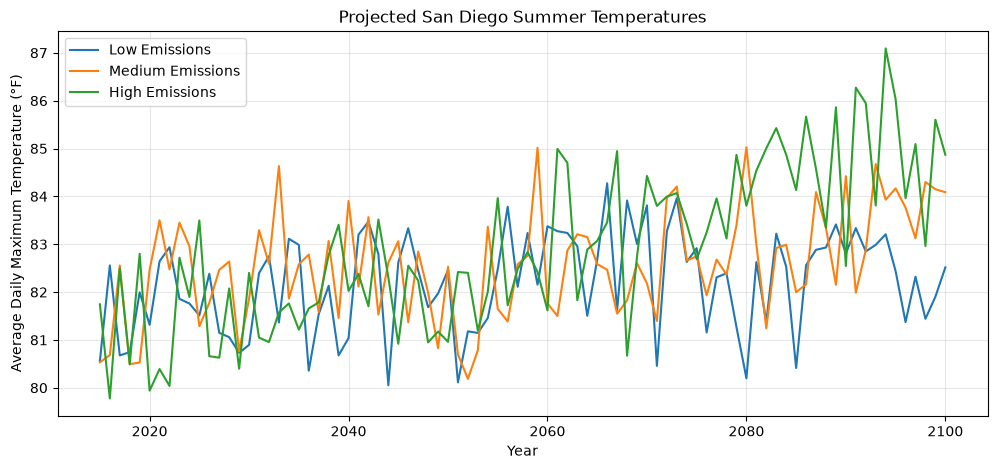

In [8]:
# Average summer maximum temperature by year
yearly_avg = summer_df.groupby("YEAR")[
    [
        "MAX_F_SSP126",
        "MAX_F_SSP245",
        "MAX_F_SSP370"
    ]
].mean()

yearly_avg.plot(figsize=(12, 5))

plt.title("Projected San Diego Summer Temperatures")
plt.xlabel("Year")
plt.ylabel("Average Daily Maximum Temperature (°F)")
plt.legend([
    "Low Emissions",
    "Medium Emissions",
    "High Emissions"
])
plt.grid(alpha=0.3)
plt.show()


In [9]:
# Save complete cleaned dataset
df.to_csv(
    "data/san_diego_cleaned.csv",
    index=False
)

# Save summer-only dataset
summer_df.to_csv(
    "data/san_diego_summer.csv",
    index=False
)

print("Cleaned CSV files saved successfully!")


Cleaned CSV files saved successfully!
